<a href="https://colab.research.google.com/github/asteriaji/MSSP6070/blob/main/WeeklyModules/Week09/Jiangyu_Ji_PARTICIPATION_ACTIVITY_Week_9_Fetch_a_website's_content_and_extract_text_from_it.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'asteriaji'
repository = 'MSSP6070'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP6070
Files in repository:
Adding_File_Structure.py
Assignment_Template.ipynb
Assignments/.gitkeep
Assignments/Assignment 1/Corrected_Version_Jiangyu_Ji_MSSP_6070_Assignment_1.ipynb
Assignments/Assignment 1/Jiangyu_Ji_MSSP_6070_Assignment_1_260930.ipynb
Assignments/Assignment 2/1
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/1_introducing_matplotlib_(1).ipynb
WeeklyModules/Week01/Week1_Jiangyu_Ji_Participation_Activity_Exercises_260828.ipynb
WeeklyModules/Week01/stats_viz (1).py
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/Week2_Jiangyu_Ji_Participation_Activity_260907__(2).ipynb
WeeklyModules/Week02/Week_2_Data_Stuctures.ipynb
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week_3_Jiangyu_Ji_PARTICIPATION_ACTIVITY_(3)_(2).ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Jiangyu_Ji_Assignment_PARTICIPATION_ACTIVITY_Week_4_Opening_a_CSV_file_and_modifying_the_c

In [11]:
import requests
from bs4 import BeautifulSoup
from PIL import Image
from io import BytesIO
import time

In [12]:
keyword = "cats"

search_url = f"https://www.flickr.com/search/?text={keyword}"

save_dir = repo_path / "WeeklyModules" / "Week09" / "Images_download"
save_dir.mkdir(parents=True, exist_ok=True)

In [13]:
headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(search_url, headers=headers, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

image_urls = []

for img in soup.find_all("img"):
    url = img.get("src") or img.get("data-src")

    if url and "live.staticflickr.com" in url:


        if url.startswith("//"):
            url = "https:" + url


        url = url.replace("\\", "")

        if url not in image_urls:
            image_urls.append(url)

print("Number of image URLs found:", len(image_urls))
print(image_urls[:10])

Number of image URLs found: 25
['https://live.staticflickr.com/4838/45925416992_c9caac8cb9_m.jpg', 'https://live.staticflickr.com/7210/6843831417_861d6996e8_w.jpg', 'https://live.staticflickr.com/3677/13545844805_170ec3746b_n.jpg', 'https://live.staticflickr.com/7302/11991979753_eac1d33dd8_m.jpg', 'https://live.staticflickr.com/3946/14934292534_32b0302f2d_m.jpg', 'https://live.staticflickr.com/8065/8168159947_94b3a89a2a_n.jpg', 'https://live.staticflickr.com/1701/24811748270_3102fc52fb_n.jpg', 'https://live.staticflickr.com/5157/14308926248_718a76913f_m.jpg', 'https://live.staticflickr.com/6100/6303228181_59371c29dc_m.jpg', 'https://live.staticflickr.com/8018/7380380362_0589be0be1_n.jpg']


In [14]:
download_headers = {
    "User-Agent": "Mozilla/5.0",
    "Referer": "https://www.flickr.com/"}

downloaded = 0

for url in image_urls:

    if downloaded >= 10:
        break

    try:
        response = requests.get(
            url,
            headers=download_headers,
            timeout=30)

        print("Status code:", response.status_code)

        response.raise_for_status()

        img = Image.open(BytesIO(response.content))
        img.verify()

        image_format = img.format.lower()

        if image_format not in ["jpeg", "png", "webp"]:
            continue

        extension = "jpg" if image_format == "jpeg" else image_format

        file_path = save_dir / f"image_{downloaded + 1}.{extension}"

        with open(file_path, "wb") as file:
            file.write(response.content)

        downloaded += 1
        print(f"Downloaded image_{downloaded}.{extension}")

        time.sleep(1)

    except Exception as e:
        print(f"Skipped: {url}")
        print("Reason:", e)

print("Total images downloaded:", downloaded)

Status code: 200
Downloaded image_1.jpg
Status code: 403
Skipped: https://live.staticflickr.com/7210/6843831417_861d6996e8_w.jpg
Reason: 403 Client Error: Forbidden for url: https://live.staticflickr.com/7210/6843831417_861d6996e8_w.jpg
Status code: 200
Downloaded image_2.jpg
Status code: 403
Skipped: https://live.staticflickr.com/7302/11991979753_eac1d33dd8_m.jpg
Reason: 403 Client Error: Forbidden for url: https://live.staticflickr.com/7302/11991979753_eac1d33dd8_m.jpg
Status code: 200
Downloaded image_3.jpg
Status code: 200
Downloaded image_4.jpg
Status code: 403
Skipped: https://live.staticflickr.com/1701/24811748270_3102fc52fb_n.jpg
Reason: 403 Client Error: Forbidden for url: https://live.staticflickr.com/1701/24811748270_3102fc52fb_n.jpg
Status code: 200
Downloaded image_5.jpg
Status code: 200
Downloaded image_6.jpg
Status code: 200
Downloaded image_7.jpg
Status code: 200
Downloaded image_8.jpg
Status code: 403
Skipped: https://live.staticflickr.com/5570/14717171470_425bd12d1b_n

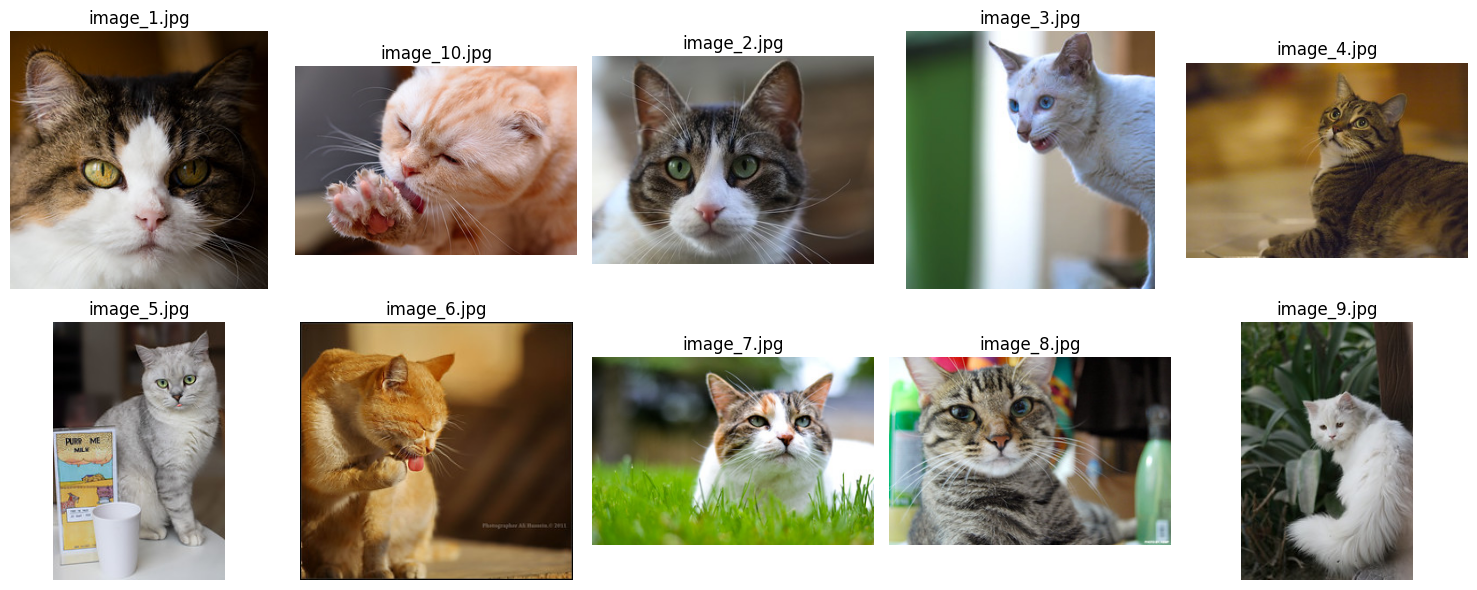

In [15]:
image_files = sorted(save_dir.glob("image_*"))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, image_file in zip(axes.flatten(), image_files):
    img = Image.open(image_file)
    ax.imshow(img)
    ax.set_title(image_file.name)
    ax.axis("off")

for ax in axes.flatten()[len(image_files):]:
    ax.axis("off")

plt.tight_layout()
plt.show()